In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from skimage.feature import peak_local_max
from tensorflow import keras
from astropy.stats import sigma_clipped_stats

MODEL_PATH = "best_PN_UNet_focal_all_grouped_v2.1.keras"
FITS_PATH = "../NGC253_4channel.fits"
NORM_PATH = "PN_UNet_normalization_v2.1.npz"
CATALOG_PATH = "../PN_CAT.csv"
ORIGINAL_FITS_PATH = "/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits"

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32
MIN_DISTANCE = 3
MATCH_TOLERANCE = 1.0

LINE_NAMES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]
SNR_COL = "OIII_SNR"
FWHM_COL = "FWHM"
M5007_COL = "m5007"
OIII_BKG_COL = "OIII_BKG"
HA_BKG_COL = "HA_BKG"

norm=np.load(NORM_PATH,allow_pickle=True)

FLUX_SCALE=float(norm["flux_scale"])
asinh_scale=norm["asinh_scale"].astype(np.float32)
CHANNEL_MEANS=norm["channel_means"].astype(np.float32)
CHANNEL_STDS=norm["channel_stds"].astype(np.float32)
PEAK_THRESHOLD=float(norm["detection_threshold"])

print("FLUX_SCALE:", FLUX_SCALE)
print("CHANNEL_MEANS:", CHANNEL_MEANS)
print("CHANNEL_STDS:", CHANNEL_STDS)
print("PEAK_THRESHOLD:", PEAK_THRESHOLD)

model = keras.models.load_model(MODEL_PATH, compile=False)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

FLUX_SCALE: 1e+18
CHANNEL_MEANS: [0.46626177 0.49649212 0.41425338 0.39273238]
CHANNEL_STDS: [0.494885   0.47129297 0.5068476  0.44680944]
PEAK_THRESHOLD: 0.45000000000000007


2026-09-12 19:01:53.701841: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-09-12 19:01:53.701854: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-09-12 19:01:53.701858: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1789232513.701866 2291296 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1789232513.701883 2291296 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model input shape : (None, 64, 64, 4)
Model output shape: (None, 64, 64, 1)


In [2]:
with fits.open(FITS_PATH) as hdul:
    data = hdul[0].data

data = np.squeeze(np.asarray(data, dtype=np.float32))
print("Original FITS shape:", data.shape)

if data.ndim != 3:
    raise ValueError(f"Expected a 3D FITS array, got shape {data.shape}")

if data.shape[-1] == 4:
    image = data
elif data.shape[0] == 4:
    image = np.moveaxis(data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis. FITS shape is {data.shape}")

print("Image shape used by network:", image.shape)
assert image.shape[-1] == 4

print("Expected channel order:")
for i, name in enumerate(LINE_NAMES):
    print(i, name)

Original FITS shape: (1733, 6080, 4)
Image shape used by network: (1733, 6080, 4)
Expected channel order:
0 Hbeta
1 OIII5007
2 Halpha
3 NII6584


In [3]:
SIGMA_CLIP=5.0
SIGMA_MAXITERS=5

def sigma_clip_channels(image,sigma=5.0,maxiters=5):
    clipped=np.empty_like(image,dtype=np.float32)

    for c in range(image.shape[-1]):
        channel=image[:,:,c].astype(np.float32)

        valid=np.isfinite(channel)
        n_invalid=np.sum(~valid)

        if not np.any(valid):
            raise ValueError(f"Channel {c} contains no finite values.")

        finite_values=channel[valid]

        mean,median,std=sigma_clipped_stats(
            finite_values,
            sigma=sigma,
            maxiters=maxiters
        )

        lower=median-sigma*std
        upper=median+sigma*std

        clean_channel=channel.copy()

        # Replace NaN and ±Inf with background level
        clean_channel[~valid]=median

        # Sigma clip
        clean_channel=np.clip(clean_channel,lower,upper)

        clipped[:,:,c]=clean_channel

        print(
            f"Channel {c}: "
            f"median={median:.4e}, "
            f"std={std:.4e}, "
            f"clip=[{lower:.4e}, {upper:.4e}], "
            f"invalid replaced={n_invalid}"
        )

    return clipped

# 1. Sigma clip + replace invalid values
image_clipped=sigma_clip_channels(
    image,
    sigma=SIGMA_CLIP,
    maxiters=SIGMA_MAXITERS
)

# 2. Flux scaling
image_scaled=image_clipped*np.float32(FLUX_SCALE)

# 3. Asinh transform
image_transformed=np.arcsinh(
    image_scaled/asinh_scale[None,None,:]
)

# 4. Z-score using TRAINING statistics
image_norm=(
    image_transformed-CHANNEL_MEANS[None,None,:]
)/CHANNEL_STDS[None,None,:]

image_norm=image_norm.astype(np.float32)

# Safety check
if not np.all(np.isfinite(image_norm)):
    raise ValueError("Normalized image still contains NaN or Inf values.")

print("\nFinal normalized image statistics:")
for c,name in enumerate(norm["line_names"]):
    x=image_norm[:,:,c]
    print(
        f"{name}: "
        f"mean={x.mean():.3f}, "
        f"std={x.std():.3f}, "
        f"min={x.min():.3f}, "
        f"max={x.max():.3f}"
    )    

Channel 0: median=9.6041e-19, std=1.5867e-18, clip=[-6.9732e-18, 8.8941e-18], invalid replaced=2099462
Channel 1: median=7.2586e-19, std=1.0354e-18, clip=[-4.4510e-18, 5.9027e-18], invalid replaced=2098866
Channel 2: median=2.4244e-18, std=6.6871e-18, clip=[-3.1011e-17, 3.5860e-17], invalid replaced=2098718
Channel 3: median=1.3288e-18, std=2.7863e-18, clip=[-1.2603e-17, 1.5260e-17], invalid replaced=2098612

Final normalized image statistics:
Hbeta: mean=0.069, std=0.908, min=-0.942, max=3.132
OIII5007: mean=0.087, std=0.964, min=-1.053, max=3.336
Halpha: mean=-0.004, std=0.900, min=-0.817, max=2.996
NII6584: mean=-0.026, std=0.874, min=-0.879, max=3.007


In [4]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(range(0, length - tile_size + 1, stride))
    final_position = length - tile_size
    if positions[-1] != final_position:
        positions.append(final_position)
    return positions


def predict_full_image(model, image, tile_size=64, stride=32, batch_size=32):
    height, width, channels = image.shape
    assert channels == 4

    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)
    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(image, ((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape
    y_positions = get_start_positions(padded_height, tile_size, stride)
    x_positions = get_start_positions(padded_width, tile_size, stride)
    coordinates = [(y, x) for y in y_positions for x in x_positions]
    print("Number of tiles:", len(coordinates))

    prediction_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    w = np.hanning(tile_size).astype(np.float32)
    weight = 0.1 + 0.9 * np.outer(w, w)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start:start + batch_size]
        batch = np.stack([
            image_padded[y:y + tile_size, x:x + tile_size, :]
            for y, x in batch_coords
        ])
        batch_predictions = model.predict(batch, verbose=0)[..., 0]

        for (y, x), pred in zip(batch_coords, batch_predictions):
            prediction_sum[y:y + tile_size, x:x + tile_size] += pred * weight
            weight_sum[y:y + tile_size, x:x + tile_size] += weight

    full_prediction = prediction_sum / np.maximum(weight_sum, 1e-12)
    return full_prediction[:height, :width]

In [5]:
pn_heatmap = predict_full_image(model, image_norm, tile_size=TILE_SIZE, stride=STRIDE, batch_size=BATCH_SIZE)
#pn_heatmap[~valid_mask] = 0.0

print("Final heatmap shape:", pn_heatmap.shape)
print("Prediction range:", pn_heatmap.min(), pn_heatmap.max())

Number of tiles: 10206


2026-09-12 19:01:56.030110: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Final heatmap shape: (1733, 6080)
Prediction range: 2.3435321e-08 0.9806432


In [6]:
def find_pn_centers(heatmap, threshold=0.3, min_distance=3):
    coords = peak_local_max(
        heatmap, min_distance=min_distance, threshold_abs=threshold, exclude_border=False)
    if len(coords) == 0:
        return np.empty((0, 3), dtype=np.float32)

    y, x = coords[:, 0], coords[:, 1]
    scores = heatmap[y, x]
    order = np.argsort(scores)[::-1]
    return np.column_stack([x[order], y[order], scores[order]])


detections = find_pn_centers(pn_heatmap, threshold=PEAK_THRESHOLD, min_distance=MIN_DISTANCE)

print("Number of PN candidates:", len(detections))
print("\n[x, y, score]")
for detection in detections:
    print(detection)

Number of PN candidates: 3409

[x, y, score]
[5.15400000e+03 1.07500000e+03 9.80643213e-01]
[5.08300000e+03 8.49000000e+02 9.68513966e-01]
[4.34400000e+03 9.52000000e+02 9.68243599e-01]
[4.99400000e+03 1.51500000e+03 9.66682434e-01]
[1.58100000e+03 9.46000000e+02 9.63700116e-01]
[2.00800000e+03 9.49000000e+02 9.61152017e-01]
[3.53600000e+03 1.15800000e+03 9.56035793e-01]
[5.62600000e+03 9.02000000e+02 9.53792036e-01]
[522.         873.           0.95318681]
[3.8810000e+03 8.1300000e+02 9.5102936e-01]
[4.82500000e+03 5.18000000e+02 9.50338542e-01]
[5.75100000e+03 1.06500000e+03 9.50270176e-01]
[4.79600000e+03 6.13000000e+02 9.48328853e-01]
[3.76200000e+03 1.24000000e+03 9.47069466e-01]
[1.87600000e+03 4.08000000e+02 9.43853796e-01]
[2.14000000e+03 4.61000000e+02 9.43030179e-01]
[5.77400000e+03 1.02900000e+03 9.36981261e-01]
[5.50200000e+03 4.71000000e+02 9.34547126e-01]
[4.42500000e+03 3.94000000e+02 9.33408797e-01]
[4.42200000e+03 7.62000000e+02 9.31239724e-01]
[2.54700000e+03 1.089000

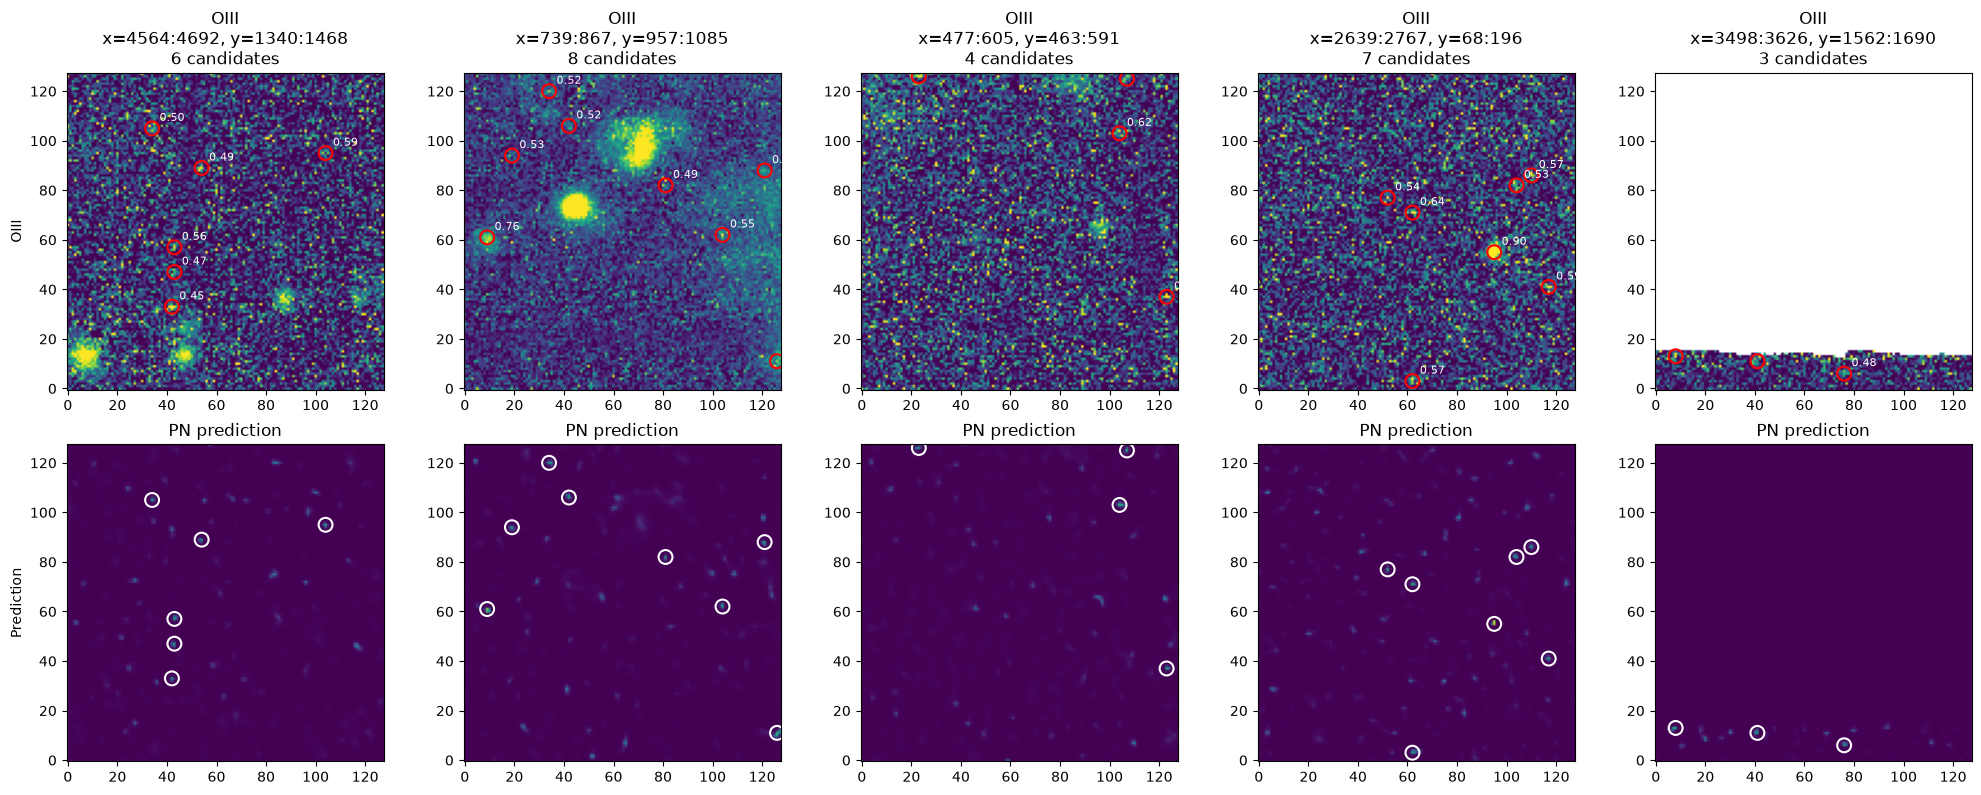

In [7]:
def plot_random_cutouts(image, pn_heatmap, detections, n_cutouts=6, cutout_size=128, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    _, axes = plt.subplots(2, n_cutouts, figsize=(4 * n_cutouts, 8))
    if n_cutouts == 1:
        axes = axes[:, None]

    for i in range(n_cutouts):
        x0 = rng.integers(0, max(1, width - cutout_size))
        y0 = rng.integers(0, max(1, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]

        if len(det) > 0:
            local_x = det[:, 0] - x0
            local_y = det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 5), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            for x, y, score in zip(local_x, local_y, det[:, 2]):
                ax.text(x + 3, y + 3, f"{score:.2f}", color="white", fontsize=8)
        ax.set_title(f"OIII\nx={x0}:{x1}, y={y0}:{y1}\n{len(det)} candidates")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
        ax.set_title("PN prediction")

    axes[0, 0].set_ylabel("OIII")
    axes[1, 0].set_ylabel("Prediction")
    plt.tight_layout()
    plt.show()


plot_random_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    n_cutouts=5, cutout_size=128, seed=100)

In [8]:
pn_catalog = pd.read_csv(CATALOG_PATH)
print(pn_catalog.head())
print("Number of catalogue PNe:", len(pn_catalog))

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    wcs = WCS(hdul["OIII5006_FLUX"].header).celestial

ra = pn_catalog["RAdeg"].to_numpy()
dec = pn_catalog["DEdeg"].to_numpy()
catalog_x, catalog_y = wcs.world_to_pixel_values(ra, dec)
pn_catalog["x"] = catalog_x
pn_catalog["y"] = catalog_y

print(pn_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head())

height, width, _ = image.shape
inside_image = (
    np.isfinite(pn_catalog["x"]) & np.isfinite(pn_catalog["y"])
    & (pn_catalog["x"] >= 0) & (pn_catalog["x"] < width)
    & (pn_catalog["y"] >= 0) & (pn_catalog["y"] < height))

catalog_in_image = pn_catalog[inside_image].copy()
print(f"Catalogue PNe inside image: {len(catalog_in_image)} / {len(pn_catalog)}")

   ID      RAdeg      DEdeg   FWHM  log_OIII_Hb  log_NII_Ha  log_SII_Ha  \
0   1  11.987615 -25.221952  0.956     1.871572    0.028113   -1.241971   
1   2  11.994759 -25.220211  0.923     1.776825   -0.548196   -1.497087   
2   3  12.021884 -25.194207  0.786     1.073425   -0.153119   -2.029765   
3   4  11.992403 -25.218152  1.080     1.436248   -0.857334   -0.846140   
4   5  11.990650 -25.220049  1.083     1.405052   -0.738616   -0.659834   

    m5007  OIII_SNR  OIII_BKG     HA_BKG  use_NII  use_SII  
0  24.724    95.148  4635.374   8483.608    False    False  
1  25.008    81.816  5043.334   8932.815    False    False  
2  24.709   132.907  3856.435  15246.028     True    False  
3  25.433    48.006  4647.829  12368.687    False    False  
4  25.789    37.488  5518.461  12392.201    False    False  
Number of catalogue PNe: 571
   ID      RAdeg      DEdeg            x           y
0   1  11.987615 -25.221952  1048.627172  768.130699
1   2  11.994759 -25.220211   938.519031  719.19

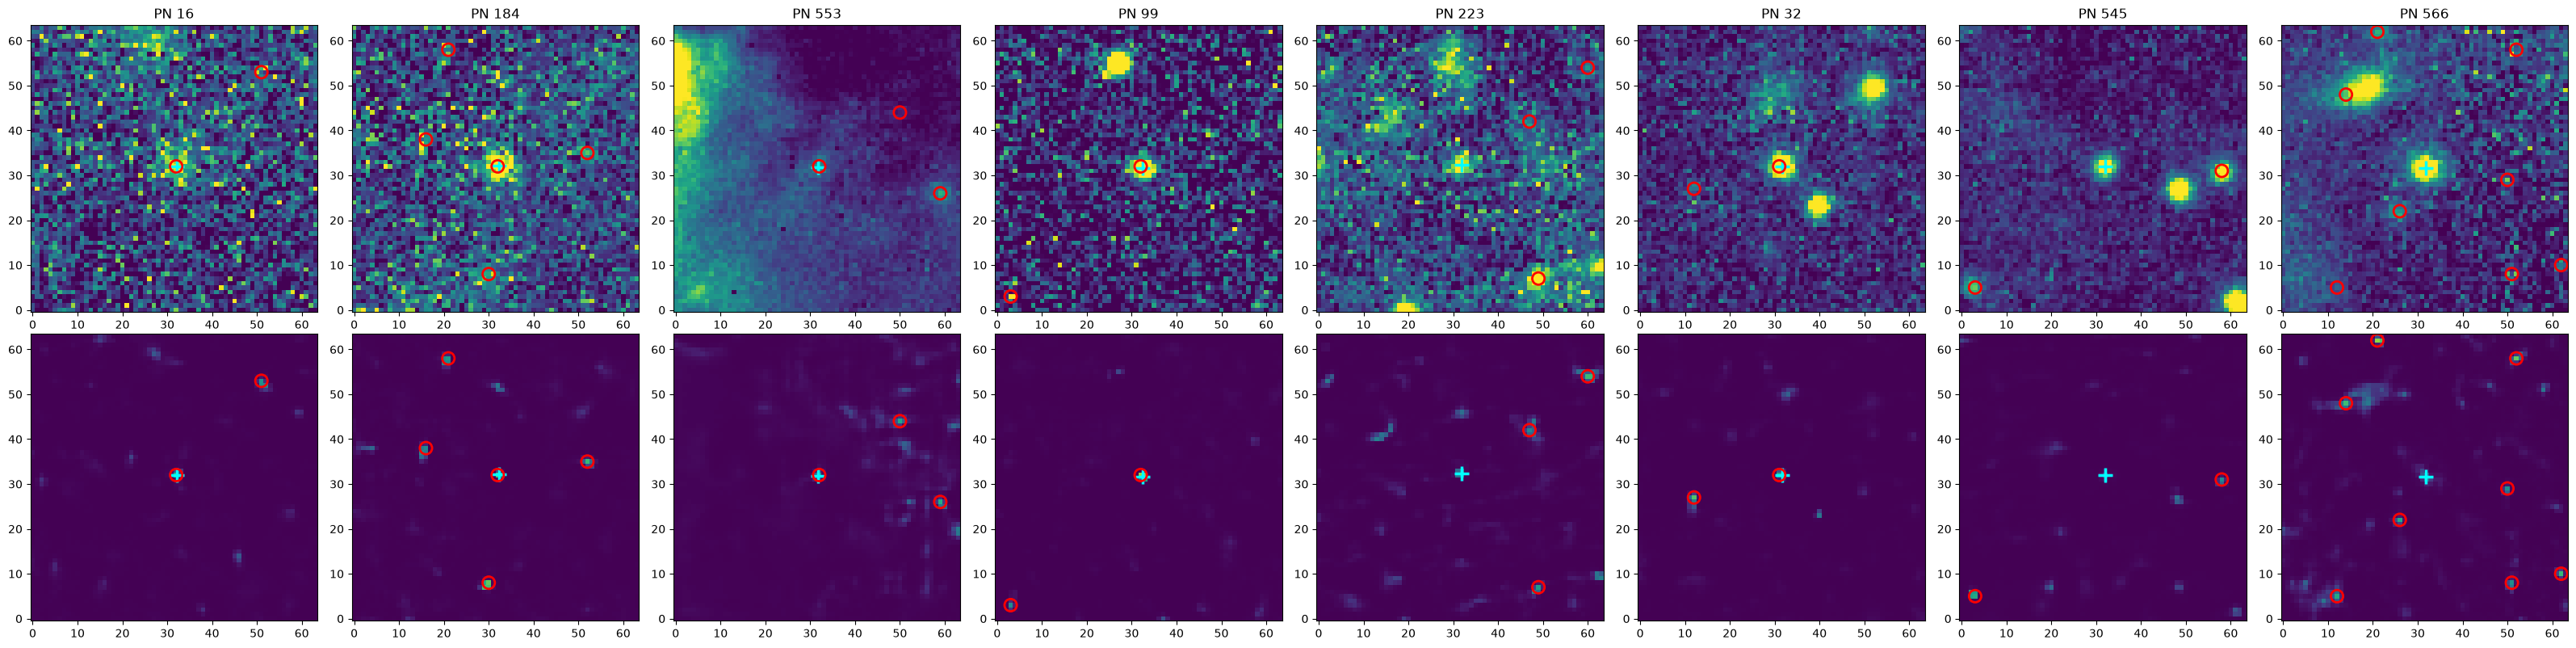

In [9]:
def plot_catalog_pn_cutouts(image, pn_heatmap, detections, catalog, n_cutouts=8, cutout_size=64, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_cutouts, len(catalog))
    selected_indices = rng.choice(len(catalog), size=n, replace=False)
    selected = catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = pn["x"], pn["y"]
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]
        model_x, model_y = det[:, 0] - x0, det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite):
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        axes[0, i].imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        axes[0, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[0, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        axes[0, i].set_title(f"PN {int(pn['ID'])}")

        axes[1, i].imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        axes[1, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[1, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)

    plt.tight_layout()
    plt.show()


plot_catalog_pn_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    catalog=catalog_in_image, n_cutouts=8, cutout_size=64, seed=60)

In [10]:
def match_catalog_to_detections(catalog, detections, tolerance=1.0):
    catalog = catalog.copy()
    cat_xy = catalog[["x", "y"]].to_numpy(dtype=np.float32)

    matched = np.zeros(len(catalog), dtype=bool)
    matched_detection_x = np.full(len(catalog), np.nan)
    matched_detection_y = np.full(len(catalog), np.nan)
    matched_detection_score = np.full(len(catalog), np.nan)
    matched_distance = np.full(len(catalog), np.nan)

    for det_x, det_y, det_score in detections:
        distances = np.sqrt((cat_xy[:, 0] - det_x)**2 + (cat_xy[:, 1] - det_y)**2)
        distances[matched] = np.inf
        nearest_index = np.argmin(distances)
        nearest_distance = distances[nearest_index]

        if nearest_distance <= tolerance:
            matched[nearest_index] = True
            matched_detection_x[nearest_index] = det_x
            matched_detection_y[nearest_index] = det_y
            matched_detection_score[nearest_index] = det_score
            matched_distance[nearest_index] = nearest_distance

    catalog["detected_by_model"] = matched
    catalog["matched_x"] = matched_detection_x
    catalog["matched_y"] = matched_detection_y
    catalog["matched_score"] = matched_detection_score
    catalog["match_distance_pix"] = matched_distance

    matched_catalog = catalog[catalog["detected_by_model"]].copy()
    missed_catalog = catalog[~catalog["detected_by_model"]].copy()
    return matched_catalog, missed_catalog


matched_catalog, missed_catalog = match_catalog_to_detections(catalog=catalog_in_image, detections=detections, tolerance=MATCH_TOLERANCE)

print("========================================")
print("CATALOGUE PN RECOVERY")
print("========================================")
print(f"Catalogue PNe inside image : {len(catalog_in_image)}")
print(f"Catalogue PNe detected     : {len(matched_catalog)}")
print(f"Catalogue PNe NOT detected : {len(missed_catalog)}")

completeness = len(matched_catalog) / len(catalog_in_image)
print(f"Catalogue completeness     : {completeness:.3f} ({100 * completeness:.1f}%)")
print("\nMissed catalogue PNe:")
display(missed_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head(20))


CATALOGUE PN RECOVERY
Catalogue PNe inside image : 571
Catalogue PNe detected     : 303
Catalogue PNe NOT detected : 268
Catalogue completeness     : 0.531 (53.1%)

Missed catalogue PNe:


,ID,RAdeg,DEdeg,x,y
7,8,11.981760,-25.224133,1147.402788,797.692968
11,12,11.995105,-25.228126,1023.897314,605.000000
13,14,12.009609,-25.210389,639.346743,704.162956
14,15,11.990313,-25.215240,938.394439,834.307171
22,23,11.975254,-25.202320,982.413014,1169.405992
25,26,11.944281,-25.215738,1526.341058,1299.408434
26,27,11.939010,-25.213882,1572.000000,1379.403225
28,29,11.923809,-25.232561,1976.000000,1274.000000
30,31,11.922783,-25.239312,2065.468844,1190.099007
32,33,11.918582,-25.246746,2202.839965,1129.181831


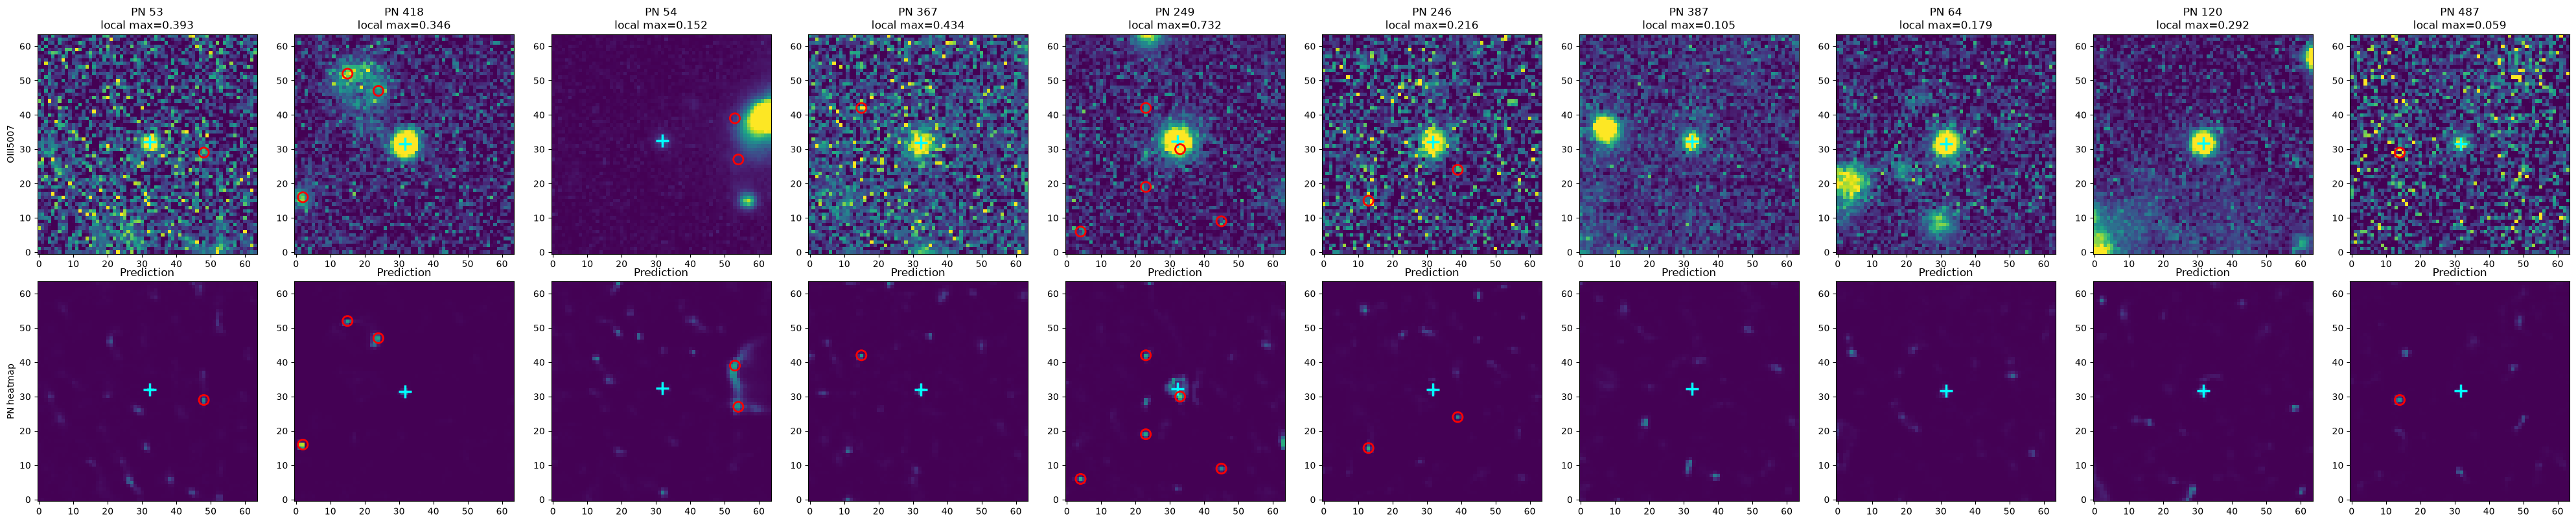

In [11]:
def plot_random_missed_pne(image, pn_heatmap, detections, missed_catalog, n_samples=10, cutout_size=64, seed=42):
    if len(missed_catalog) == 0:
        print("No missed catalogue PNe!")
        return

    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_samples, len(missed_catalog))
    selected_indices = rng.choice(len(missed_catalog), size=n, replace=False)
    selected = missed_catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = float(pn["x"]), float(pn["y"])
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1))
        det = detections[inside]
        if len(det) > 0:
            local_det_x = det[:, 0] - x0
            local_det_y = det[:, 1] - y0

        search_radius = 3
        cx, cy = int(round(xc)), int(round(yc))
        sx0, sx1 = max(0, cx - search_radius), min(width, cx + search_radius + 1)
        sy0, sy1 = max(0, cy - search_radius), min(height, cy + search_radius + 1)
        local_max_score = np.max(pn_heatmap[sy0:sy1, sx0:sx1])

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title(f"PN {pn['ID']}\nlocal max={local_max_score:.3f}")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title("Prediction")

    axes[0, 0].set_ylabel("OIII5007")
    axes[1, 0].set_ylabel("PN heatmap")
    plt.tight_layout()
    plt.show()


plot_random_missed_pne(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    missed_catalog=missed_catalog, n_samples=10, cutout_size=64, seed=42)

In [12]:
evaluated_catalog = pd.concat([matched_catalog, missed_catalog], ignore_index=True)
if "ID" in evaluated_catalog.columns:
    evaluated_catalog = evaluated_catalog.sort_values("ID").reset_index(drop=True)

print(evaluated_catalog.columns.tolist())
print("Detected:", evaluated_catalog["detected_by_model"].sum())
print("Missed:", (~evaluated_catalog["detected_by_model"]).sum())

['ID', 'RAdeg', 'DEdeg', 'FWHM', 'log_OIII_Hb', 'log_NII_Ha', 'log_SII_Ha', 'm5007', 'OIII_SNR', 'OIII_BKG', 'HA_BKG', 'use_NII', 'use_SII', 'x', 'y', 'detected_by_model', 'matched_x', 'matched_y', 'matched_score', 'match_distance_pix']
Detected: 303
Missed: 268


OIII S/N statistics
Detected: N=303, median=55.46, mean=60.00
Missed:   N=268, median=78.74, mean=86.75


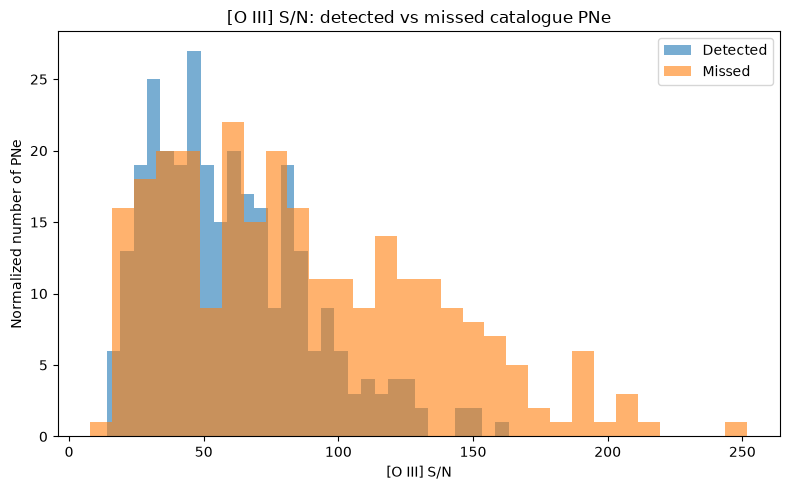

In [13]:
snr_data = evaluated_catalog[np.isfinite(evaluated_catalog[SNR_COL])].copy()
detected_snr = snr_data.loc[snr_data["detected_by_model"], SNR_COL]
missed_snr = snr_data.loc[~snr_data["detected_by_model"], SNR_COL]

print("OIII S/N statistics")
print("====================")
print(f"Detected: N={len(detected_snr)}, median={np.median(detected_snr):.2f}, mean={np.mean(detected_snr):.2f}")
print(f"Missed:   N={len(missed_snr)}, median={np.median(missed_snr):.2f}, mean={np.mean(missed_snr):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_snr, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_snr, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("[O III] S/N")
plt.ylabel("Normalized number of PNe")
plt.title("[O III] S/N: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,snr_bin,snr_median,snr_min,snr_max,n_total,n_detected,completeness
0,"(7.941999999999999, 29.588]",23.7235,7.943,29.580,72,41,0.569444
1,"(29.588, 39.928]",34.3230,29.612,39.766,71,49,0.690141
2,"(39.928, 50.03]",45.4180,40.090,49.946,71,47,0.661972
3,"(50.03, 63.627]",59.0285,50.058,63.627,72,45,0.625000
4,"(63.627, 78.328]",71.2990,63.653,78.257,71,42,0.591549
5,"(78.328, 93.237]",84.1190,78.540,93.231,71,39,0.549296
6,"(93.237, 124.521]",108.9750,93.243,124.476,71,30,0.422535
7,"(124.521, 251.791]",148.1835,124.536,251.791,72,10,0.138889


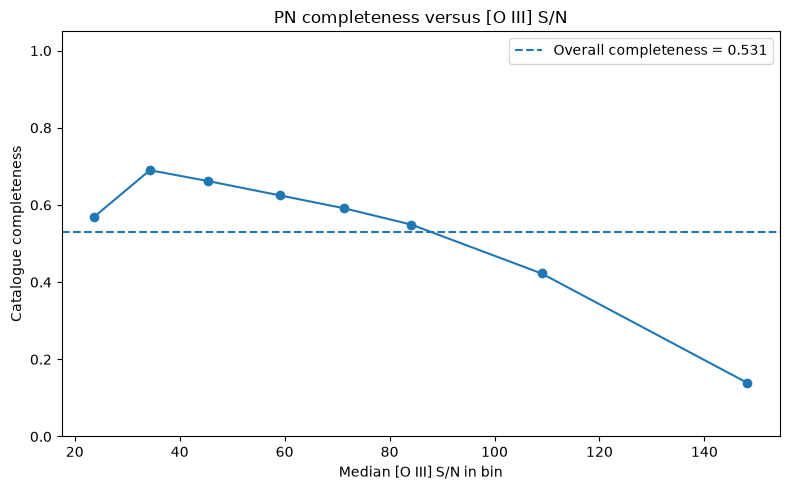

In [14]:
snr_data["snr_bin"] = pd.qcut(snr_data[SNR_COL], q=8, duplicates="drop")
snr_completeness = (
    snr_data.groupby("snr_bin", observed=True)
    .agg(
        snr_median=(SNR_COL, "median"),
        snr_min=(SNR_COL, "min"),
        snr_max=(SNR_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
snr_completeness["completeness"] = snr_completeness["n_detected"] / snr_completeness["n_total"]
display(snr_completeness)

plt.figure(figsize=(8, 5))
plt.plot(snr_completeness["snr_median"], snr_completeness["completeness"], marker="o")
plt.axhline(completeness, linestyle="--", label=f"Overall completeness = {completeness:.3f}")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Catalogue completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

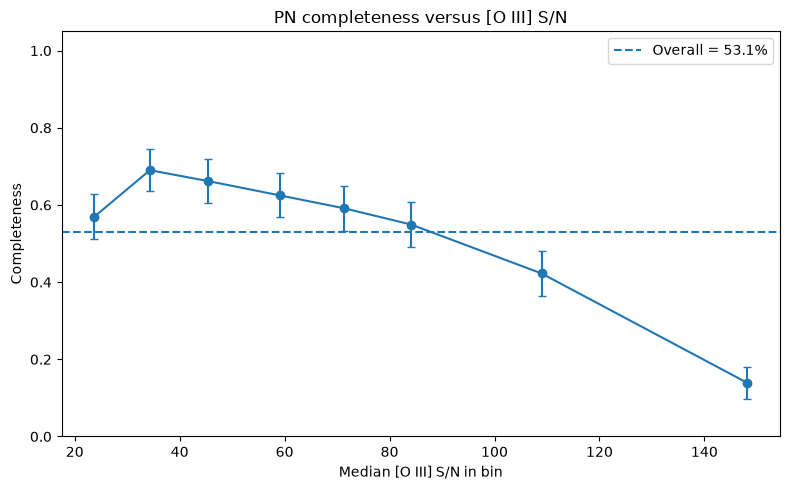

In [15]:
snr_completeness["error"] = np.sqrt(snr_completeness["completeness"] * 
                                    (1 - snr_completeness["completeness"]) / snr_completeness["n_total"])

plt.figure(figsize=(8, 5))
plt.errorbar(
    snr_completeness["snr_median"], snr_completeness["completeness"],
    yerr=snr_completeness["error"], marker="o", capsize=3)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

FWHM statistics
Detected: N=303, median=0.766, mean=0.797
Missed:   N=268, median=0.752, mean=0.792


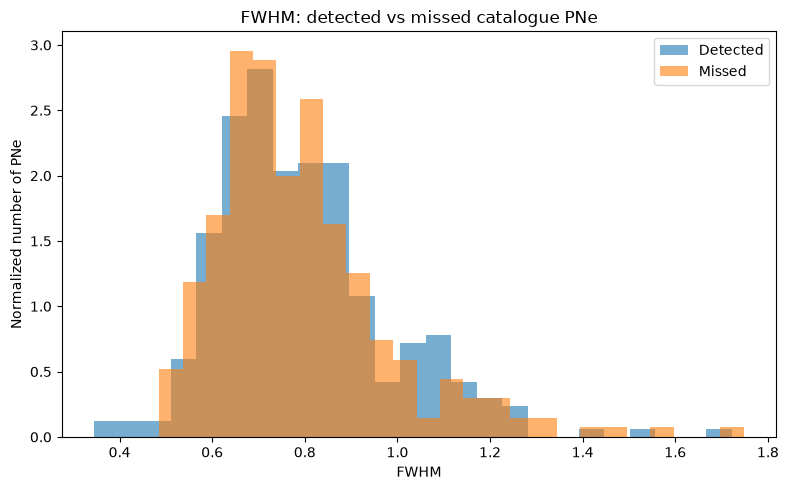

In [16]:
fwhm_data = evaluated_catalog[np.isfinite(evaluated_catalog[FWHM_COL])].copy()
detected_fwhm = fwhm_data.loc[fwhm_data["detected_by_model"], FWHM_COL]
missed_fwhm = fwhm_data.loc[~fwhm_data["detected_by_model"], FWHM_COL]

print("FWHM statistics")
print("===============")
print(f"Detected: N={len(detected_fwhm)}, median={np.median(detected_fwhm):.3f}, mean={np.mean(detected_fwhm):.3f}")
print(f"Missed:   N={len(missed_fwhm)}, median={np.median(missed_fwhm):.3f}, mean={np.mean(missed_fwhm):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_fwhm, bins=25, alpha=0.6, density=True, label="Detected")
plt.hist(missed_fwhm, bins=25, alpha=0.6, density=True, label="Missed")
plt.xlabel("FWHM")
plt.ylabel("Normalized number of PNe")
plt.title("FWHM: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,fwhm_bin,fwhm_median,fwhm_min,fwhm_max,n_total,n_detected,completeness,error
0,"(0.344, 0.616]",0.577,0.345,0.616,75,38,0.506667,0.057730
1,"(0.616, 0.662]",0.639,0.617,0.661,68,40,0.588235,0.059682
2,"(0.662, 0.709]",0.692,0.663,0.709,73,35,0.479452,0.058471
3,"(0.709, 0.76]",0.734,0.710,0.760,70,36,0.514286,0.059737
4,"(0.76, 0.821]",0.792,0.761,0.821,72,32,0.444444,0.058561
5,"(0.821, 0.876]",0.845,0.822,0.875,70,43,0.614286,0.058179
6,"(0.876, 1.012]",0.924,0.876,1.010,71,36,0.507042,0.059333
7,"(1.012, 1.748]",1.119,1.012,1.748,72,43,0.597222,0.057801


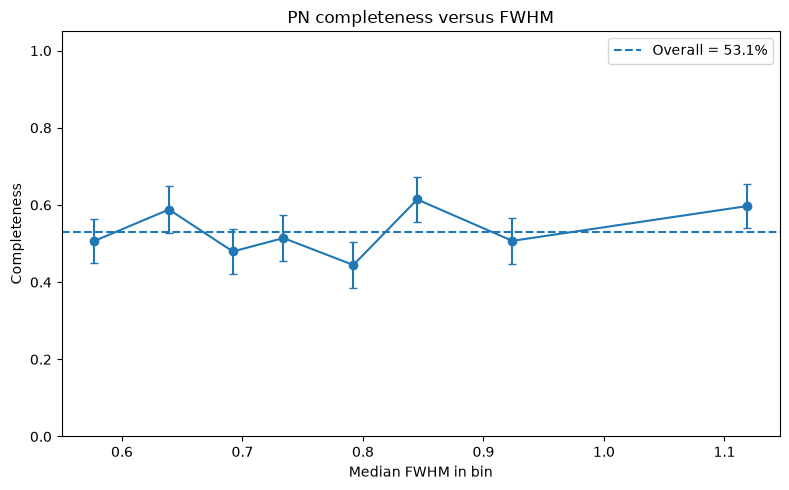

In [17]:
fwhm_data["fwhm_bin"] = pd.qcut(fwhm_data[FWHM_COL], q=8, duplicates="drop")
fwhm_completeness = (
    fwhm_data.groupby("fwhm_bin", observed=True)
    .agg(
        fwhm_median=(FWHM_COL, "median"),
        fwhm_min=(FWHM_COL, "min"),
        fwhm_max=(FWHM_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
fwhm_completeness["completeness"] = fwhm_completeness["n_detected"] / fwhm_completeness["n_total"]
fwhm_completeness["error"] = np.sqrt(
    fwhm_completeness["completeness"] * (1 - fwhm_completeness["completeness"])
    / fwhm_completeness["n_total"]
)
display(fwhm_completeness)

plt.figure(figsize=(8, 5))
plt.errorbar(
    fwhm_completeness["fwhm_median"], fwhm_completeness["completeness"],
    yerr=fwhm_completeness["error"], marker="o", capsize=3
)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median FWHM in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus FWHM")
plt.legend()
plt.tight_layout()
plt.show()


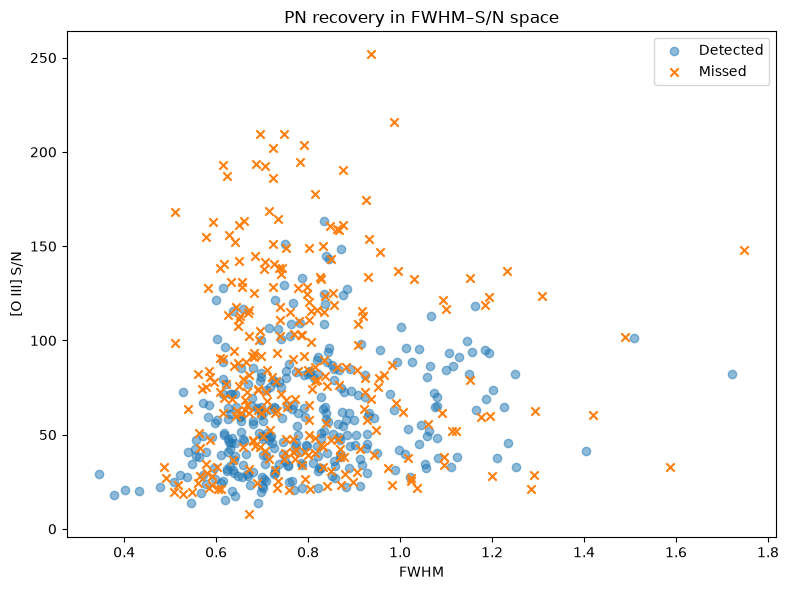

In [18]:
combined = evaluated_catalog[
    np.isfinite(evaluated_catalog[SNR_COL]) & np.isfinite(evaluated_catalog[FWHM_COL])
].copy()
det = combined["detected_by_model"]

plt.figure(figsize=(8, 6))
plt.scatter(combined.loc[det, FWHM_COL], combined.loc[det, SNR_COL], alpha=0.5, label="Detected")
plt.scatter(combined.loc[~det, FWHM_COL], combined.loc[~det, SNR_COL], marker="x", label="Missed")
plt.xlabel("FWHM")
plt.ylabel("[O III] S/N")
plt.title("PN recovery in FWHM–S/N space")
plt.legend()
plt.tight_layout()
plt.show()


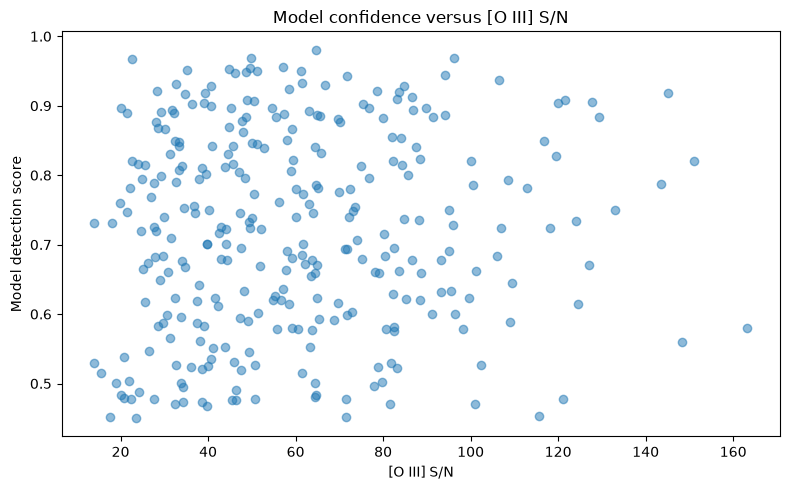

In [19]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["matched_score"], alpha=0.5)
plt.xlabel("[O III] S/N")
plt.ylabel("Model detection score")
plt.title("Model confidence versus [O III] S/N")
plt.tight_layout()
plt.show()


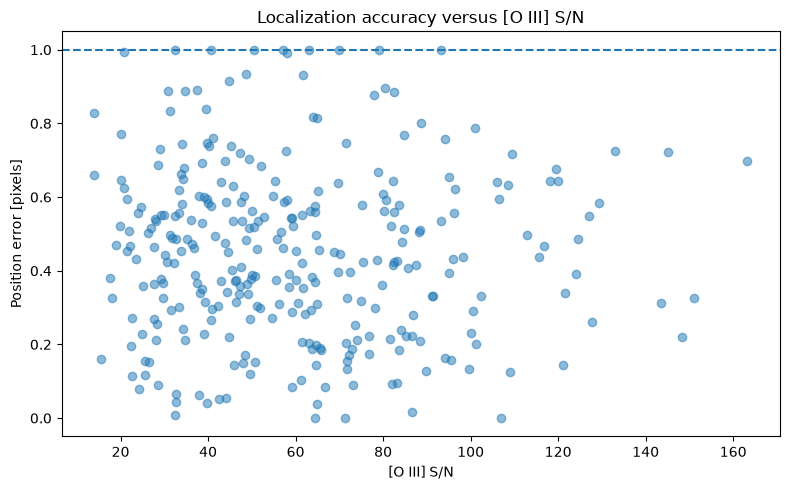

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["match_distance_pix"], alpha=0.5)
plt.axhline(MATCH_TOLERANCE, linestyle="--")
plt.xlabel("[O III] S/N")
plt.ylabel("Position error [pixels]")
plt.title("Localization accuracy versus [O III] S/N")
plt.tight_layout()
plt.show()

OIII M5007 statistics
Detected: N=303, median=25.57, mean=25.61
Missed:   N=268, median=25.08, mean=25.10


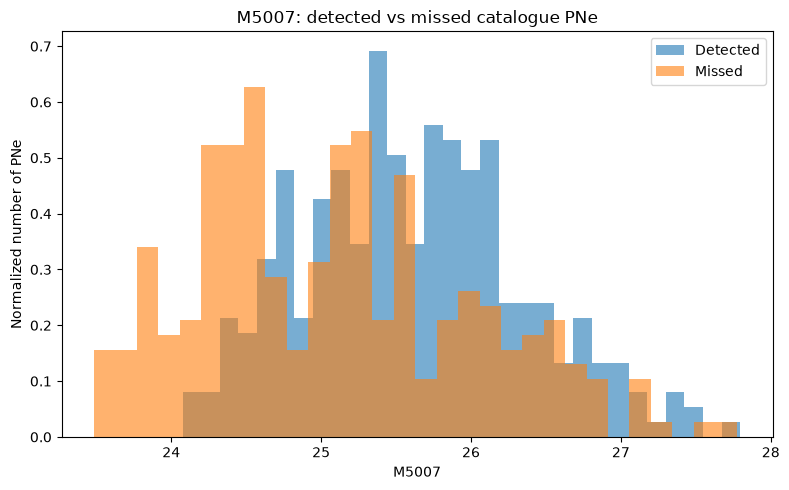

In [21]:
m5007_data = evaluated_catalog[np.isfinite(evaluated_catalog[M5007_COL])].copy()
detected_m5007 = m5007_data.loc[m5007_data["detected_by_model"], M5007_COL]
missed_m5007 = m5007_data.loc[~m5007_data["detected_by_model"], M5007_COL]

print("OIII M5007 statistics")
print("====================")
print(f"Detected: N={len(detected_m5007)}, median={np.median(detected_m5007):.2f}, mean={np.mean(detected_m5007):.2f}")
print(f"Missed:   N={len(missed_m5007)}, median={np.median(missed_m5007):.2f}, mean={np.mean(missed_m5007):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_m5007, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_m5007, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("M5007")
plt.ylabel("Normalized number of PNe")
plt.title("M5007: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

OIII BKG statistics
Detected: N=303, median=3837.14, mean=4515.31
Missed:   N=268, median=4481.67, mean=5499.73
HA BKG statistics
Detected: N=303, median=14544.43, mean=21105.34
Missed:   N=268, median=18978.96, mean=31141.75


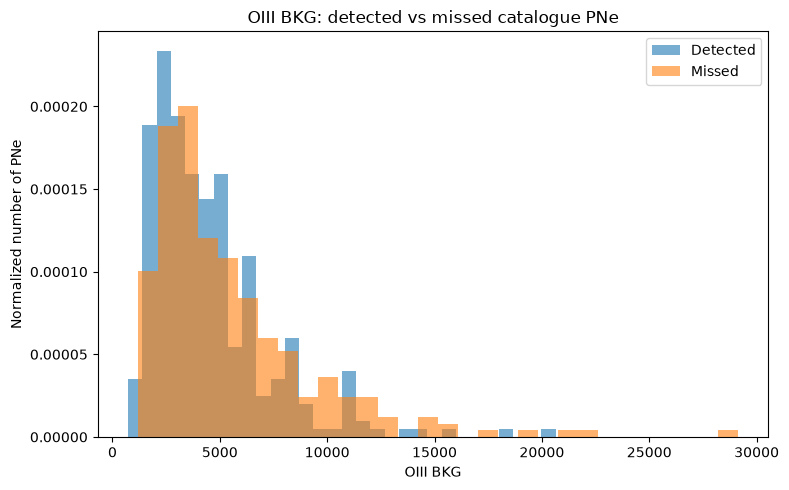

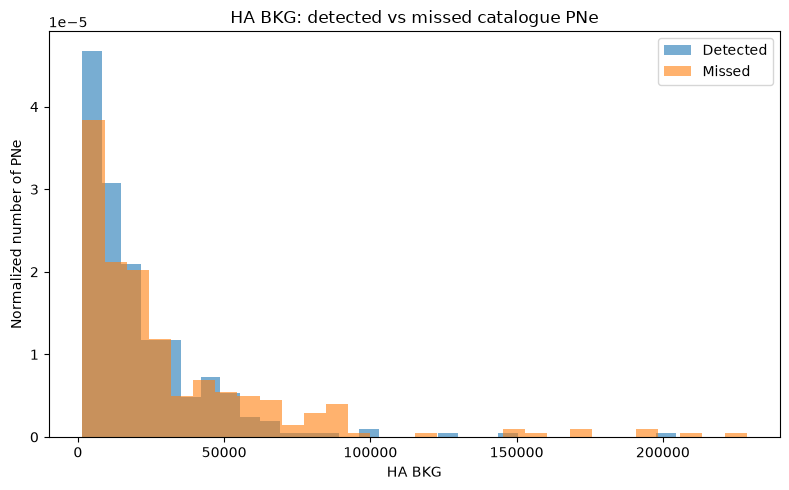

In [22]:
oiii_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[OIII_BKG_COL])].copy()
detected_oiii_bkg = oiii_bkg_data.loc[oiii_bkg_data["detected_by_model"], OIII_BKG_COL]
missed_oiii_bkg = oiii_bkg_data.loc[~m5007_data["detected_by_model"], OIII_BKG_COL]

ha_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[HA_BKG_COL])].copy()
detected_ha_bkg = ha_bkg_data.loc[ha_bkg_data["detected_by_model"], HA_BKG_COL]
missed_ha_bkg = ha_bkg_data.loc[~m5007_data["detected_by_model"], HA_BKG_COL]

print("OIII BKG statistics")
print("====================")
print(f"Detected: N={len(detected_oiii_bkg)}, median={np.median(detected_oiii_bkg):.2f}, mean={np.mean(detected_oiii_bkg):.2f}")
print(f"Missed:   N={len(missed_oiii_bkg)}, median={np.median(missed_oiii_bkg):.2f}, mean={np.mean(missed_oiii_bkg):.2f}")

print("HA BKG statistics")
print("====================")
print(f"Detected: N={len(detected_ha_bkg)}, median={np.median(detected_ha_bkg):.2f}, mean={np.mean(detected_ha_bkg):.2f}")
print(f"Missed:   N={len(missed_ha_bkg)}, median={np.median(missed_ha_bkg):.2f}, mean={np.mean(missed_ha_bkg):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_oiii_bkg, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_oiii_bkg, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("OIII BKG")
plt.ylabel("Normalized number of PNe")
plt.title("OIII BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(detected_ha_bkg, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_ha_bkg, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("HA BKG")
plt.ylabel("Normalized number of PNe")
plt.title("HA BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

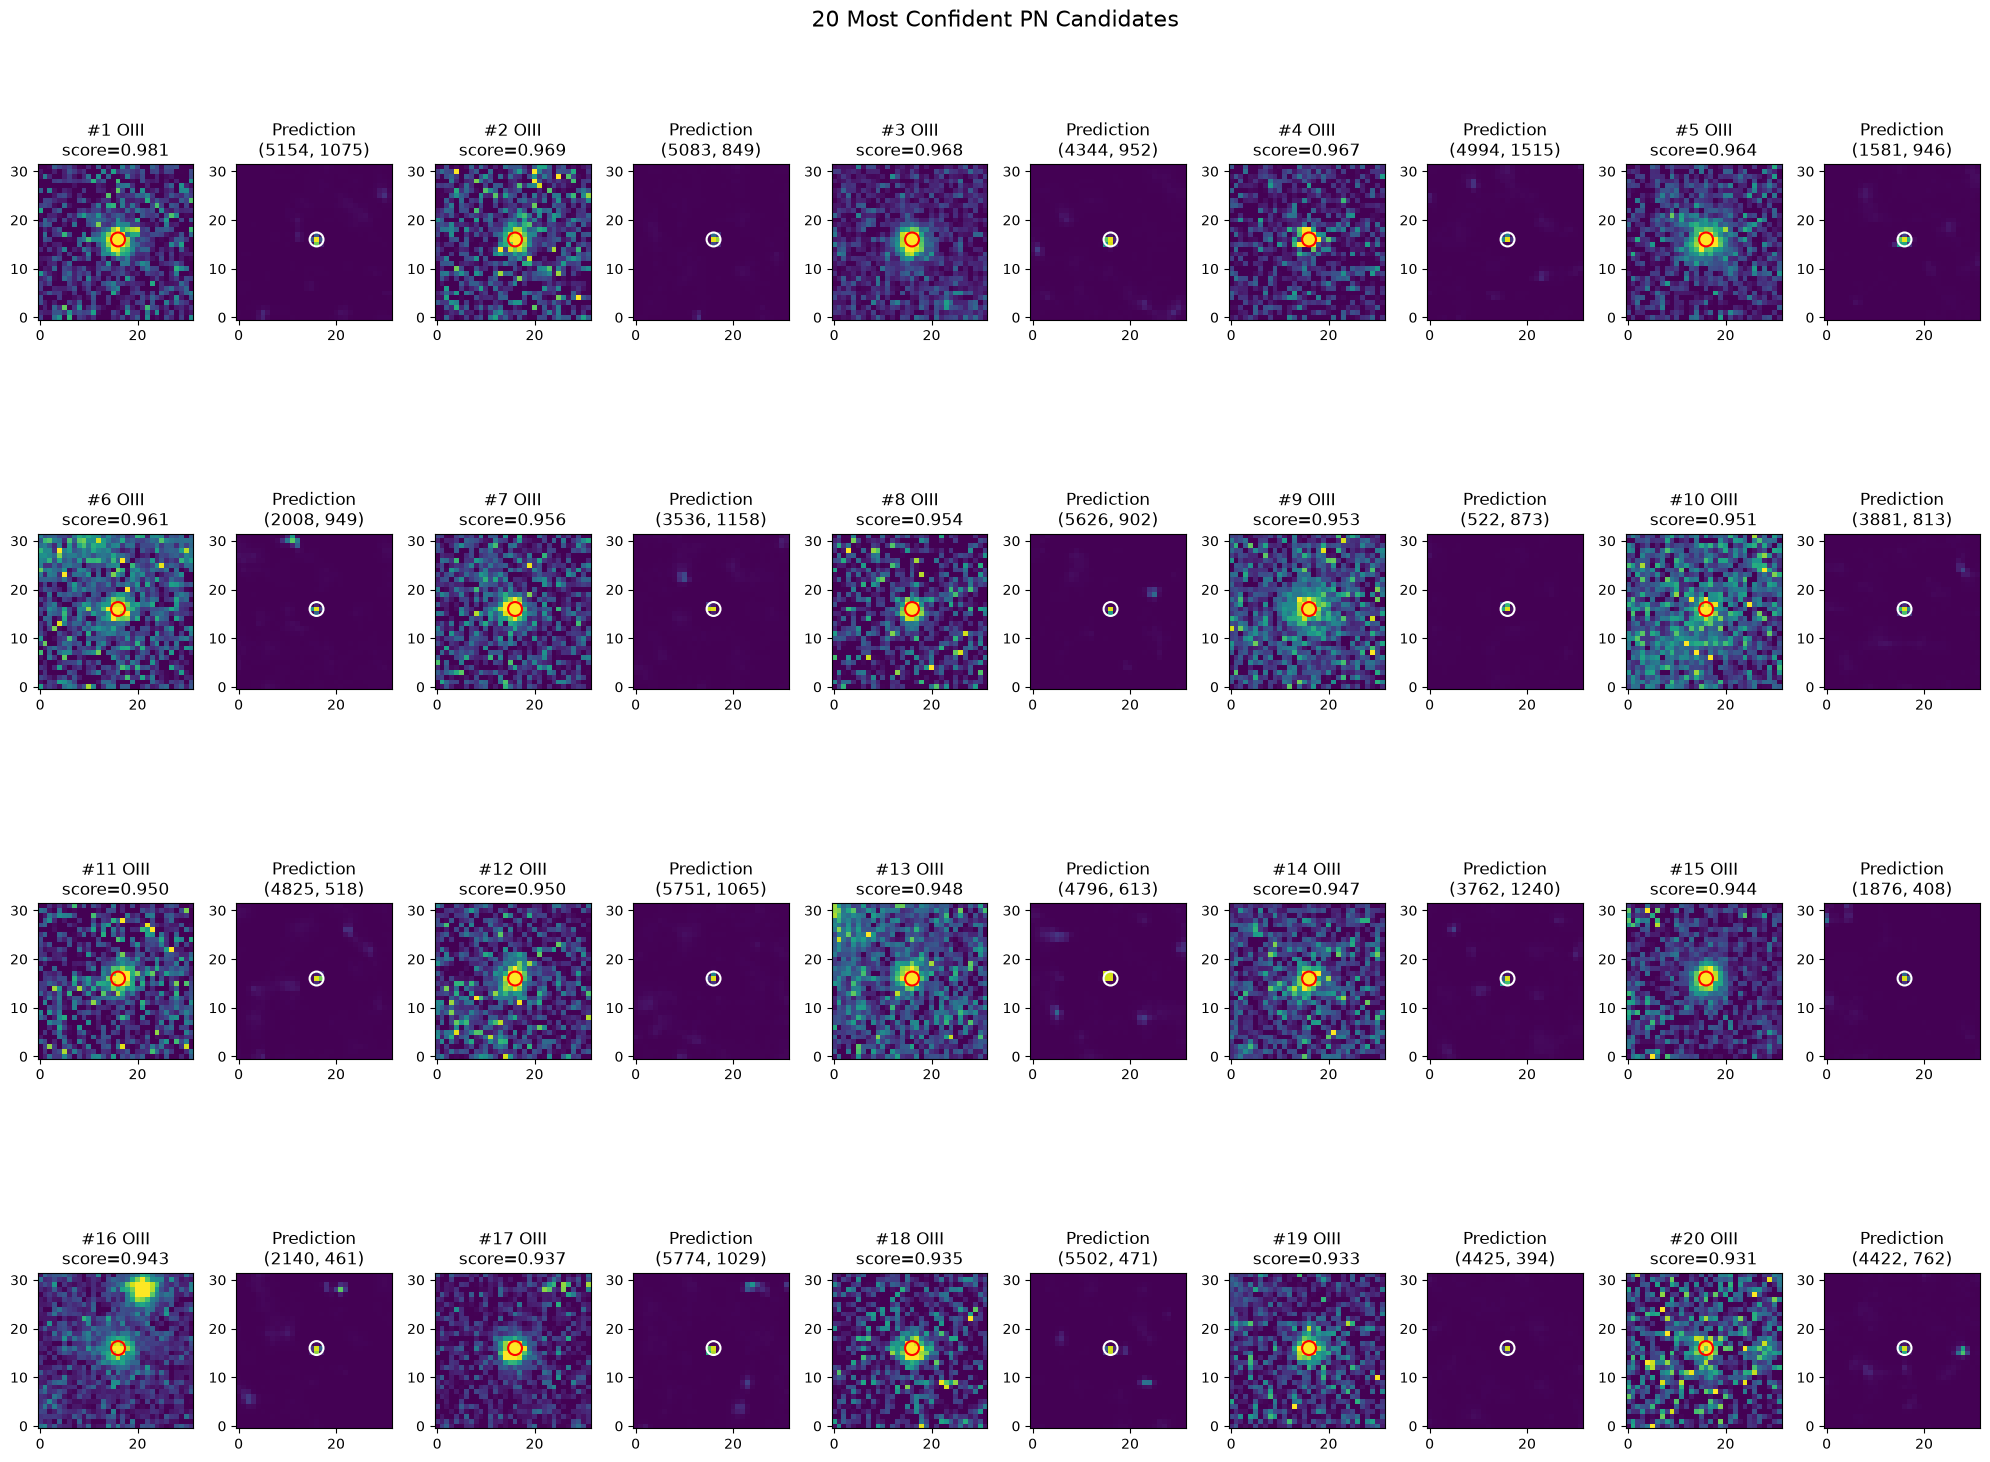

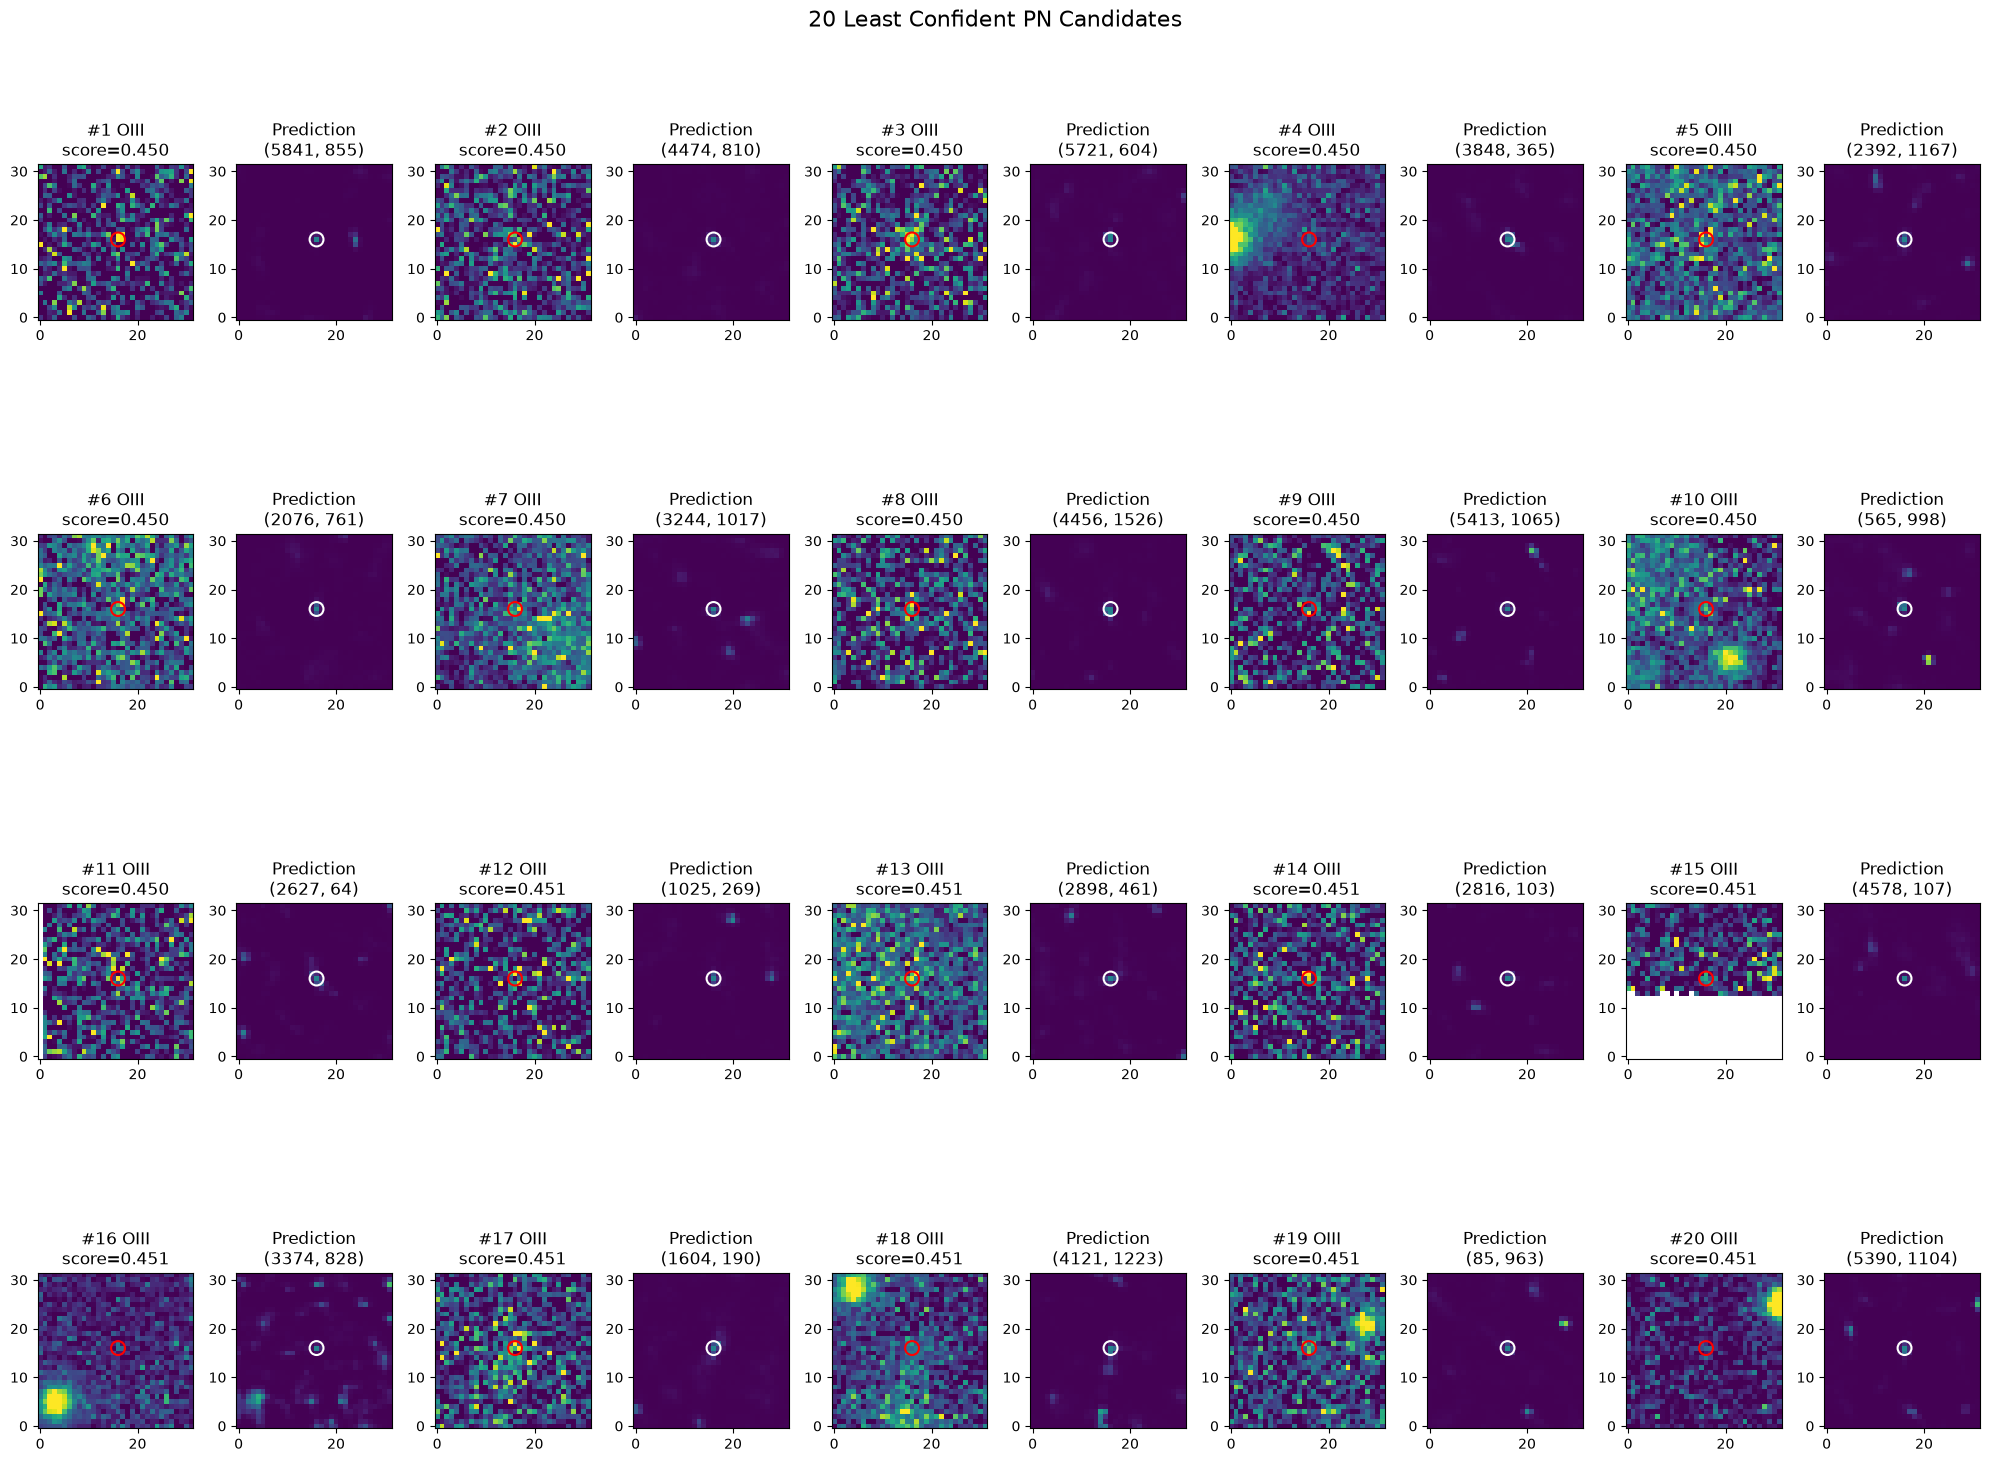

In [23]:
def plot_confidence_cutouts(image, pn_heatmap, detections, n_sources=20, cutout_size=32):
    oiii = image[..., 1]
    height, width = pn_heatmap.shape
    half = cutout_size // 2

    def plot_group(selected, title):
        n = len(selected)
        n_rows = int(np.ceil(n / 5))
        fig, axes = plt.subplots(n_rows, 10, figsize=(20, 4 * n_rows))
        axes = np.atleast_2d(axes)

        for i, (x, y, score) in enumerate(selected):
            x, y = int(round(x)), int(round(y))
            x0 = max(0, min(x - half, width - cutout_size))
            y0 = max(0, min(y - half, height - cutout_size))
            x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

            oiii_cutout = oiii[y0:y1, x0:x1]
            pred_cutout = pn_heatmap[y0:y1, x0:x1]
            local_x, local_y = x - x0, y - y0

            finite = oiii_cutout[np.isfinite(oiii_cutout)]
            vmin, vmax = np.percentile(finite, [8, 99]) if len(finite) else (0, 1)

            row, col = i // 5, (i % 5) * 2

            ax = axes[row, col]
            ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            ax.set_title(f"#{i + 1} OIII\nscore={score:.3f}")

            ax = axes[row, col + 1]
            ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
            ax.set_title(f"Prediction\n({x}, {y})")

        for ax in axes.flat[2 * n:]:
            ax.axis("off")

        fig.suptitle(title, fontsize=16)
        plt.tight_layout()
        plt.show()

    n = min(n_sources, len(detections))
    plot_group(detections[:n], f"{n} Most Confident PN Candidates")
    plot_group(detections[-n:][::-1], f"{n} Least Confident PN Candidates")


plot_confidence_cutouts(
    image=image,
    pn_heatmap=pn_heatmap,
    detections=detections,
    n_sources=20,
    cutout_size=32
)